# **Import Libraries**

In [1]:
#Packages
import pandas as pd #import pandas library as 'pd'
import numpy as np #import numpy library as 'np'
import matplotlib.pyplot as plt #import matplotlib.pyplot as 'plt'
import seaborn as sns #import seaborn as 'sns'
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_breast_cancer #import Breast Cancer Dataset from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_style('whitegrid') #Enable grid box in visualization

# **Load Dataset**

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

In [3]:
X.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='object')

In [4]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [5]:
print(y.head(30)) #indicates 0 or 1 malignant or benign in first 40 rows

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    1
20    1
21    1
22    0
23    0
24    0
25    0
26    0
27    0
28    0
29    0
dtype: int64


In [6]:
unique, counts = np.unique(y, return_counts=True)
print("Class labels:", unique)
print("Target names:", data.target_names)

Class labels: [0 1]
Target names: ['malignant' 'benign']


# **Data Preprocessing**

In [7]:
# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# **Exploratory Data Analysis**

In [8]:
# Convert scaled features to DataFrame
df = pd.DataFrame(X_scaled, columns=data.feature_names)

## Heatmap

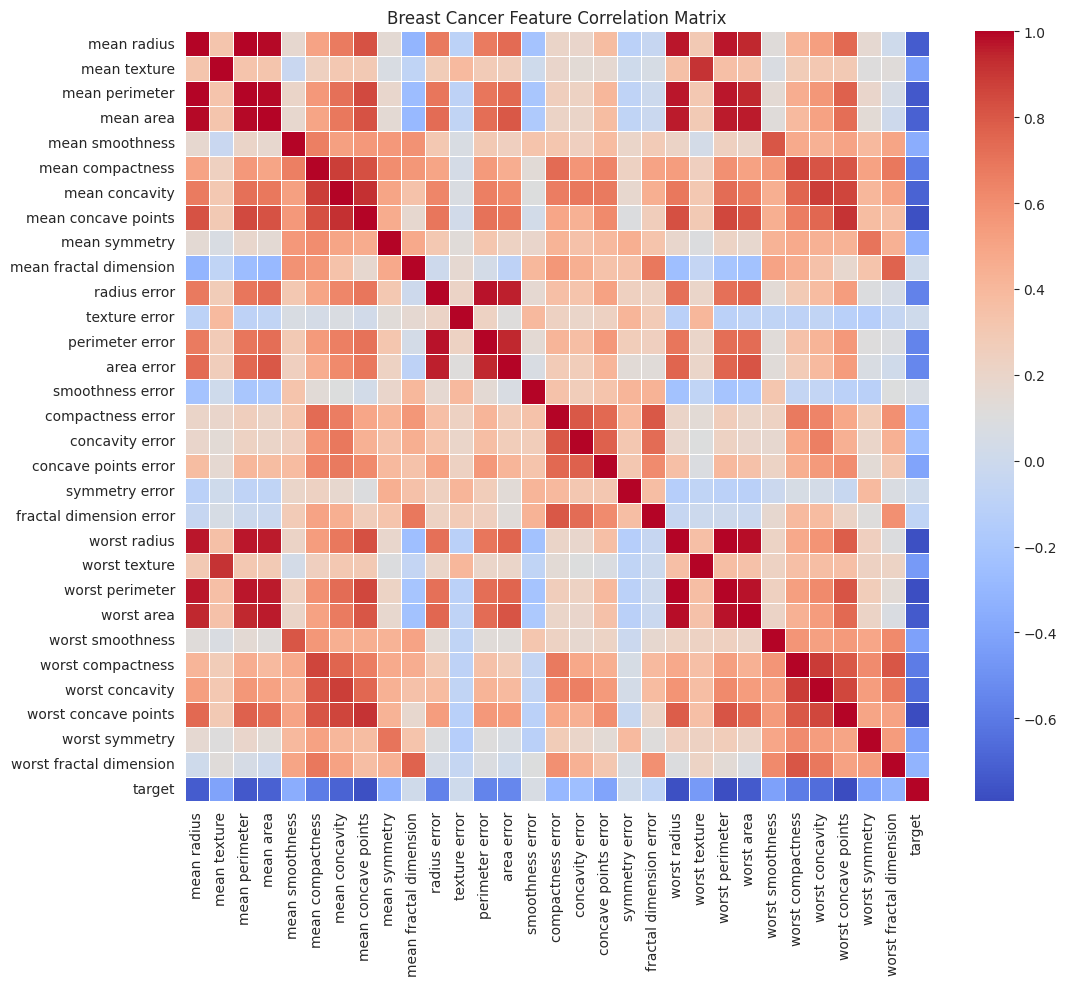

In [9]:
df['target'] = y
corr_matrix = df.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', linewidths=0.5)
plt.title("Breast Cancer Feature Correlation Matrix")
plt.show()

## Pairplot

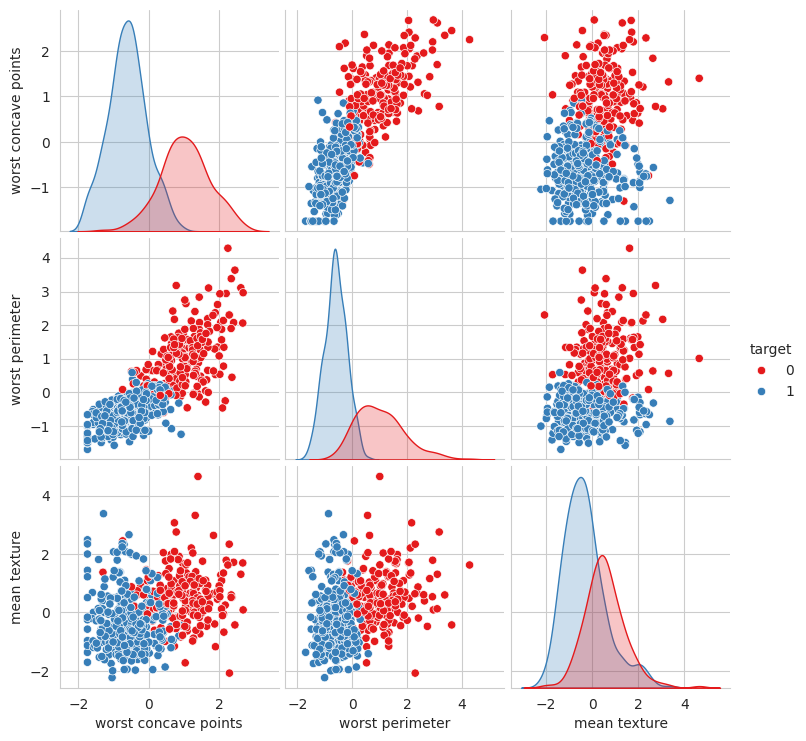

In [10]:
# Add target labels to the DataFrame
df['target'] = y
# Visualize relationships between a 3 key selected features
sns.pairplot(df, vars=['worst concave points', 'worst perimeter', 'mean texture'], hue='target', palette='Set1')

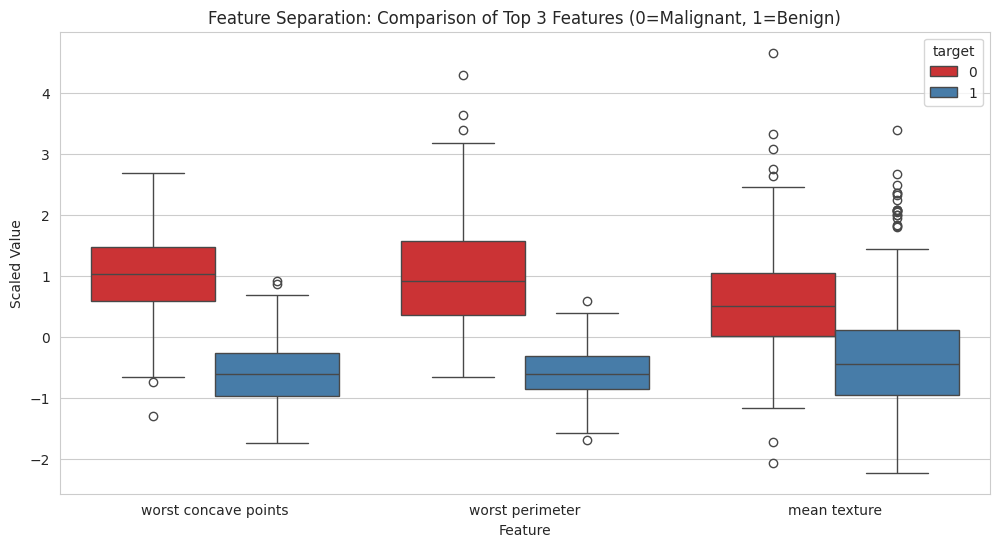

In [11]:
# Assign the top 3 feature in plot_features
plot_features = ['worst concave points', 'worst perimeter', 'mean texture']

# Melt the dataframe: This stacks the 3 columns into one long column allowing us to compare them side-by-side on the X-axis
df_melted = df.melt(id_vars='target', value_vars=plot_features, var_name='Feature', value_name='Scaled Value')

plt.figure(figsize=(12, 6))
sns.boxplot(x='Feature', y='Scaled Value', hue='target', data=df_melted, palette='Set1')
plt.title('Feature Separation: Comparison of Top 3 Features (0=Malignant, 1=Benign)')
plt.show()



---



# **K-NN Classifier**

###Full feature

In [12]:
df_scaled = pd.DataFrame(X_scaled, columns=data.feature_names)

In [13]:
X_scaled_full = X_scaled
y = data.target

In [14]:
X_train_full , X_test_full, y_train, y_test = train_test_split(X_scaled_full, y, test_size=0.2, random_state=42)

In [15]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_full, y_train)

KNeighborsClassifier()

#### Evaluation & Prediction

In [16]:
y_pred = knn.predict(X_test_full)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.2f}')
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('Classification Report:\n',
classification_report(y_test, y_pred))

Accuracy: 0.95
Confusion Matrix:
 [[40  3]
 [ 3 68]]
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.93      0.93        43
           1       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



### Reduced feature

In [17]:
df_scaled = pd.DataFrame(X_scaled, columns=data.feature_names)

In [18]:
#Top 3 features
selected_features = ['worst concave points', 'worst perimeter', 'mean texture']
X_scaled_selected = df_scaled[selected_features]

In [19]:
#Split Dataset (Full features)
X_train_sel, X_test_sel, y_train, y_test = train_test_split(X_scaled_selected, y, test_size=0.2, random_state=42)

In [20]:
#value of k is the 5 nearest neighbours
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_sel, y_train)

KNeighborsClassifier()

#### Evaluation & Prediction

In [21]:
y_pred = knn.predict(X_test_sel)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.2f}')
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('Classification Report:\n',
classification_report(y_test, y_pred))

Accuracy: 0.96
Confusion Matrix:
 [[39  4]
 [ 1 70]]
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.91      0.94        43
           1       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## **Logistic Regression**

### Full feature

In [134]:
df_scaled = pd.DataFrame(X_scaled, columns=data.feature_names)

In [135]:
X_scaled_full = X_scaled
y = data.target

In [136]:
X_train_full , X_test_full, y_train, y_test = train_test_split(X_scaled_full, y, test_size=0.2, random_state=42)

In [137]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_full, y_train)

LogisticRegression(random_state=42)

In [138]:
y_pred = log_reg.predict(X_test_full)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.2f}')
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('Classification Report:\n',
classification_report(y_test, y_pred))

Accuracy: 0.97
Confusion Matrix:
 [[41  2]
 [ 1 70]]
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



### Reduced Feature

In [139]:
df_scaled = pd.DataFrame(X_scaled, columns=data.feature_names)

In [140]:
#Top 3 features
selected_features = ['worst concave points', 'worst perimeter', 'mean texture']
X_scaled_selected = df_scaled[selected_features]

In [141]:
#Split Dataset (Full features)
X_train_sel, X_test_sel, y_train, y_test = train_test_split(X_scaled_selected, y, test_size=0.2, random_state=42)

In [142]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_sel, y_train)

LogisticRegression(random_state=42)

In [143]:
y_pred = log_reg.predict(X_test_sel)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.2f}')
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('Classification Report:\n',
classification_report(y_test, y_pred))

Accuracy: 0.97
Confusion Matrix:
 [[40  3]
 [ 0 71]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.93      0.96        43
           1       0.96      1.00      0.98        71

    accuracy                           0.97       114
   macro avg       0.98      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



## **Visualization of Decision Boundary**

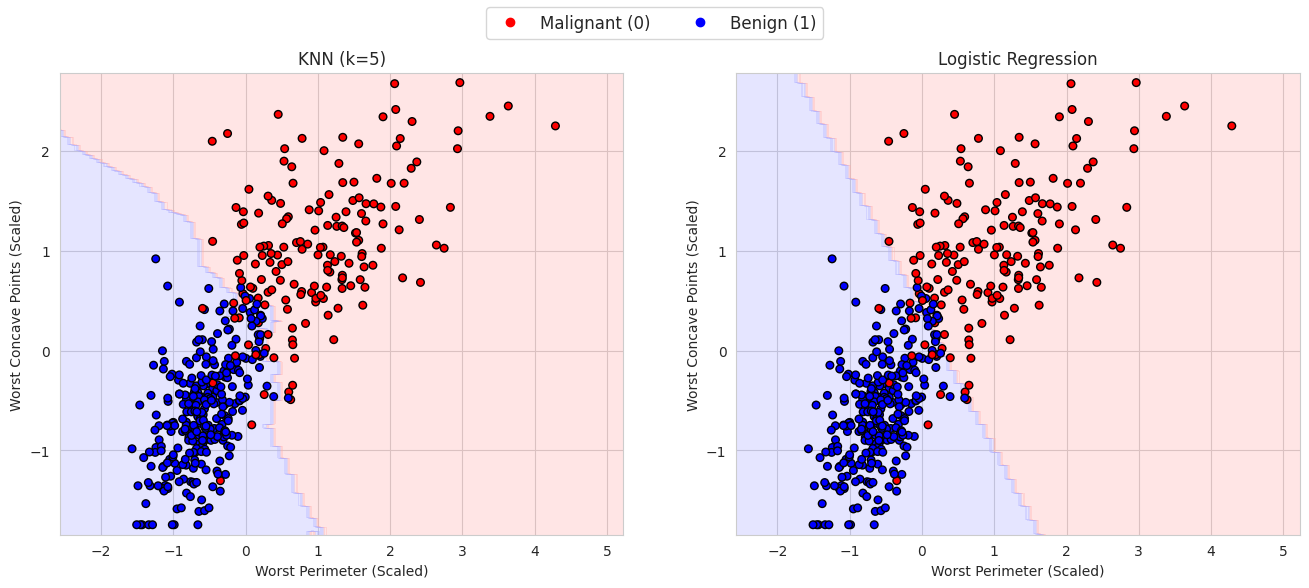

In [155]:
# Only 2 features is used, worst concave points & worst perimeter to generate 2D graphs.
# X index 0 = worst concave points
# X index 1 = worst perimeter
X_vis = X_train_sel.iloc[:, [1, 0]].values  # Select 'worst perimeter' and 'worst concave points' for visualization
y_vis = y_train

# Retrain Models on these 2 features
clf_knn = KNeighborsClassifier(n_neighbors=5).fit(X_vis, y_vis)
clf_log = LogisticRegression(random_state=42).fit(X_vis, y_vis)

# Create the Background Grid (The "Mesh")
x_min, x_max = X_vis[:, 0].min() - 1, X_vis[:, 0].max() + 1
y_min, y_max = X_vis[:, 1].min() - 0.1, X_vis[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.01))

def plot_decision_boundary(model, title, ax):
    # Predict for every single pixel on the grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Add zones(Red vs Blue background) to scatterplot
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(['#FFAAAA', '#AAAAFF']))

    # Create dots, the dots determine the number of patient
    scatter = ax.scatter(X_vis[:, 0], X_vis[:, 1], c=y_vis, edgecolors='k', s=30, cmap=ListedColormap(['#FF0000', '#0000FF']))

    ax.set_title(title)
    ax.set_xlabel('Worst Perimeter (Scaled)')
    ax.set_ylabel('Worst Concave Points (Scaled)')
    return scatter


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))# Generate the Plot
plot_decision_boundary(clf_knn, "KNN (k=5)", ax1)# Plot KNN
scatter = plot_decision_boundary(clf_log, "Logistic Regression", ax2)# Plot Logistic Regression
handles, _ = scatter.legend_elements()
fig.legend(handles, ['Malignant (0)', 'Benign (1)'], loc='upper center', ncol=2, fontsize=12)# Add Legend
plt.show()